In [1]:
import netCDF4 as nc4
import glob
import intake

import os
from collections import defaultdict

import xarray as xr
import numpy as np
import pandas as pd
import math

from scipy import signal
from scipy import stats

import dask 

#import xesmf as xe
import regionmask 

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.mpl
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

from matplotlib.patches import Patch

import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

In [2]:
from dask.distributed import Client
client = Client(threads_per_worker=1)
client

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.10/lib/python3.11/site-packages/distributed/diagnostics/nvml.py:14: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml
/g/data/xp65/public/apps/med_conda/envs/analysis3-25.10/lib/python3.11/site-packages/distributed/node.py:173: ResourceWarning: unclosed <socket.socket fd=61, family=2, type=1, proto=6, laddr=('0.0.0.0', 0)>
  if retries_left < 1:
/g/data/xp65/public/apps/med_conda/envs/analysis3-25.10/lib/python3.11/site-packages/distributed/node.py:187: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 34805 instead
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-25.10/lib/python3.11/site-packages/distributed/diagnostics/nvml.py:14: FutureWarning: The pynvml package is deprec

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/34805/status,
Dashboard: /proxy/34805/status,Workers: 28
Total threads: 28,Total memory: 251.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:44365,Workers: 0
Dashboard: /proxy/34805/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:44147,Total threads: 1
Dashboard: /proxy/39367/status,Memory: 8.97 GiB
Nanny: tcp://127.0.0.1:40519,


In [3]:
#This cell must be in all notebooks!
#It allows us to run all the notebooks at once, note that the following cell has a tag "parameters" which allows us to pass in arguments externally using papermill (see mkfigs.sh for details)

#parameters

### USER EDIT start
esm_file='/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-11-08-2025-25km-beta-om3-new-um-params/cm3-demo-datastore/cm3-demo-datastore.json'
dpi=300
### USER EDIT stop

import os
from matplotlib import rcParams
%matplotlib inline
rcParams['figure.dpi']= dpi

plotfolder=f"/scratch/{os.environ['PROJECT']}/{os.environ['USER']}/nesp/"
os.makedirs(plotfolder, exist_ok=True)

 # a similar cell under this means it's being run in batch
print("ESM datastore path: ",esm_file)
print("Plot folder path: ",plotfolder)

ESM datastore path:  /g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-11-08-2025-25km-beta-om3-new-um-params/cm3-demo-datastore/cm3-demo-datastore.json
Plot folder path:  /scratch/eg3/cxc548/nesp/


In [4]:
def detrend_1d(y, deg=1):
    x = np.arange(y.size)  
    z = np.polyfit(x, y, deg)  
    trend = np.polyval(z, x) 
    return y - trend + np.mean(y) 

def detrend_wrap(da, deg=1):
    return xr.apply_ufunc(
        detrend_1d, da,
        input_core_dims=[['time']],  
        vectorize=True,  
 #       dask='parallelized',  
        kwargs={'deg': deg}  
    )

def detrend_monthly(da, deg=1):
    da = da.chunk({'time': -1})  # ensure time is one chunk

    return da.groupby('time.month').apply(
        lambda x: xr.apply_ufunc(
            detrend_1d, x,
            input_core_dims=[['time']],
            output_core_dims=[['time']],
            vectorize=True,
            dask='parallelized',
            output_dtypes=[float],
            kwargs={'deg': deg}
        )
    )
def get_seasonal_means(da, seasons):
    da_season_mean = {}
    for season in seasons:
        if season == 'DJF':
            da_shifted = da.copy()
            da_shifted['time'] = da_shifted['time'].astype('datetime64[ns]') + np.timedelta64(31, 'D')
            da_season = da_shifted.where(da_shifted['time.season'] == 'DJF', drop=True)
            da_season_mean[season] = da_season.groupby('time.year').mean(dim='time')
        else:
                da_season = da.where(da['time.season'] == season, drop=True)
                da_season_mean[season] = da_season.groupby('time.year').mean(dim='time')
    return da_season_mean
    
# def get_seasonal_means(da, seasons):
#     da_season_mean = {}
#     for season in seasons:
#         if season == 'DJF':
#             da_season_tmp = da.where(da['time.season'] == 'DJF')
#             da_season = da_season_tmp.rolling(min_periods=3, center=True, time=3).mean()
#             da_season_mean[season] = da_season.groupby('time.year').mean(dim='time')
#         else:
#             da_season = da.where(da['time.season'] == season, drop=True)
#             da_season_mean[season] = da_season.groupby('time.year').mean(dim='time')
#     return da_season_mean

def convert_units(da):
    # Convert Kelvin to Celsius
    if da.attrs.get('units') == 'K':
        da = da - 273.15
        da.attrs['units'] = '°C' 
    
    # Convert Pascal to hectoPascal
    elif da.attrs.get('units') == 'Pa':
        da = da / 100.
        da.attrs['units'] = 'hPa' 

    # Convert kg m-2 s-1 to mm/day
    elif da.attrs.get('units') == 'kg m-2 s-1':
        da = da*86400.
        da.attrs['units'] = 'mm/day' 
    return da

def calcMonAnom(da):
    monclim = da.groupby('time.month').mean('time')
    monanom = da.groupby('time.month') - monclim
    return monanom 

def area_weighted_mean(da, lat_south, lat_north, lon_left, lon_right):
    weights = np.cos(np.deg2rad(da.lat))
    weights.name = 'weights'
    da_area_mean = da.sel(lat=slice(lat_south,lat_north),lon=slice(lon_left,lon_right)).weighted(weights).mean(('lat','lon'))
    return da_area_mean

def linr(a,b):
    slope, intercept, r_value, p_value, std_err = stats.linregress(a,b)
    return slope, p_value

<span style="color: blue; font-size: 18px; font-weight: bold;">1) Read in variables 

In [5]:
import warnings
warnings.filterwarnings('ignore')


#datastore_path = "/g/data/ol01/access-om3-output/access-om3-025/MC_25km_jra_ryf-1.0-beta/experiment_datastore.json"
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

In [6]:
def available_variables(datastore):
    """Return a pandas dataframe summarising the variables in a datastore"""
    variable_columns = [col for col in datastore.df.columns if "variable" in col]
    return (
        datastore.df[variable_columns]
        .explode(variable_columns)
        .drop_duplicates()
        .set_index("variable")
        .sort_index()
    )

In [57]:
datastore_filtered = datastore.search(realm="atmos", frequency="1mon")

for col in COLUMNS_WITH_ITERABLES:
    datastore_filtered.df[col] = datastore_filtered.df[col].astype("object").map(lambda x: list(map(str, x)))

df = available_variables(datastore_filtered)
df.index




Index(['fld_s00i004', 'fld_s00i010', 'fld_s00i012', 'fld_s00i023',
       'fld_s00i024', 'fld_s00i025', 'fld_s00i028', 'fld_s00i029',
       'fld_s00i031', 'fld_s00i032',
       ...
       'rho_level_height', 'sigma_rho', 'sigma_theta', 'sigma_theta_0',
       'sigma_theta_1', 'sigma_theta_2', 'theta_level_height',
       'theta_level_height_0', 'theta_level_height_1', 'theta_level_height_2'],
      dtype='object', name='variable', length=245)

In [ ]:
ts_ds = datastore.search(variable="fld_s00i024", frequency="1mon")
    
ts = ts_ds.to_dask(
    xarray_open_kwargs={
        "chunks": "auto",
   },
    xarray_combine_by_coords_kwargs={
        'compat' : 'override',
        'data_vars': 'minimal',
        'coords': 'minimal'
    })
    
pr_ds = datastore.search(variable="fld_s05i216", frequency="1mon")
pr = pr_ds.to_dask(
    xarray_open_kwargs={
        "chunks": "auto",
   },
    xarray_combine_by_coords_kwargs={
        'compat' : 'override',
        'data_vars': 'minimal',
        'coords': 'minimal'
    })

psl_ds = datastore.search(variable="fld_s16i222")#, frequency="1mon")
psl = psl_ds.to_dask(
    xarray_open_kwargs={
        "chunks": "auto",
   },
    xarray_combine_by_coords_kwargs={
        'compat' : 'override',
        'data_vars': 'minimal',
        'coords': 'minimal'
    })

In [9]:
#print(ts)
cm3_ts = convert_units(ts['fld_s00i024'].chunk({'time': -1}))
cm3_pr = convert_units(pr['fld_s05i216'].chunk({'time': -1}))



In [10]:
cm2_dir = "/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/atm/netCDF/"

#cm2_ts_xr = xr.open_mfdataset(cm2_dir+"*pm000*mon.nc",concat_dim="time",combine="nested").fld_s00i024 #, 'lat': 36, 'lon': 64})
#cm2_pr_xr = xr.open_mfdataset(cm2_dir+"*pm000*mon.nc",concat_dim="time",combine="nested").fld_s05i216 #, 'lat': 36, 'lon': 64})
cm2_ts_xr = xr.open_dataset("/g/data/eg3/cxc548/nesp/ACCESS_testing/atmos_fields_cm225km_001-141.nc",decode_times=True).ts
cm2_pr_xr = xr.open_dataset("/g/data/eg3/cxc548/nesp/ACCESS_testing/atmos_fields_cm225km_001-141.nc",decode_times=True).pr


#cm2_ts = convert_units(xr.open_mfdataset(files,concat_dim="time",combine="nested").fld_s00i024).chunk({'time': -1})#, 'lat': 36, 'lon': 64})

In [11]:
cm2_ts = convert_units(cm2_ts_xr).chunk({'time': -1})
cm2_pr = convert_units(cm2_pr_xr).chunk({'time': -1})

In [12]:
# %%time

# #cm3 = xr.open_dataset("/scratch/p66/fc6164/SeptSpinUpA/ts_Amon_ACCESS-ESM1-5__r1i1p1f1_gn_060201-088912.nc",decode_times=True).ts
# #cm3 = cm3.sel(time=slice('0610','0790'))
# cm3 = xr.open_dataset("/scratch/p66/fc6164/CM3/ts_Amon_ACCESS-ESM1-5__r1i1p1f1_gn_109201-142712.nc",decode_times=True).ts
# cm3 = cm3.sel(time=slice('1110','1315'))
# cm3_ts = convert_units(cm3)#.chunk({'time': -1}) #degC
# cm3_ts = cm3_ts.transpose("time","lat","lon")


# ##take last 200 
# cm2_dir = "/g/data/fs38/publications/CMIP6/CMIP/CSIRO/ACCESS-ESM1-5//r1i1p1f1/Amon/"
# cm2_ts = convert_units(xr.open_mfdataset(cm2_dir+"ts/gn/latest/ts_Amon_ACCESS-ESM1-5__r1i1p1f1_gn_*.nc",
#                                            concat_dim="time",combine="nested").ts.isel(time=slice(-2400, None))).chunk({'time': -1})
# #, 'lat': 36, 'lon': 64}) 

obs = xr.open_dataset("/g/data/ct11/access-nri/replicas/esmvaltool/obsdata-v2/Tier2/HadCRUT5/OBS_HadCRUT5_ground_5.0.1.0-analysis_Amon_tas_185001-202112.nc",decode_times=True).tas
obs = obs.sel(time=slice('1980','2014'))

obs_ts = convert_units(obs)

In [13]:
#cm2_ts = cm2_ts.chunk({'lon':96})

#print(obs_ts.mean(['lat','lon']).values)

In [14]:


cm3_ts_monanom = calcMonAnom(cm3_ts)

cm2_ts_monanom = calcMonAnom(cm2_ts)
obs_ts_monanom = calcMonAnom(obs_ts)


cm3_ts_monanom_dt = detrend_monthly(cm3_ts_monanom, deg=1)

cm2_ts_monanom_dt = detrend_monthly(cm2_ts_monanom, deg=1)

obs_ts_dt = detrend_monthly(obs_ts_monanom,deg=1)

In [15]:
cm3_nino34 = area_weighted_mean(cm3_ts_monanom_dt, lat_south=-5, lat_north=5, lon_left=190, lon_right=240).compute()

cm2_nino34 = area_weighted_mean(cm2_ts_monanom_dt, lat_south=-5, lat_north=5, lon_left=190, lon_right=240).compute()
obs_nino34 = area_weighted_mean(obs_ts_dt, lat_south=-5, lat_north=5, lon_left=190, lon_right=240).compute()


In [16]:
cm3_dmi = (area_weighted_mean(cm3_ts_monanom_dt, lat_south=-10, lat_north=10, lon_left=50, lon_right=70) - area_weighted_mean(cm3_ts_monanom_dt, lat_south=-10, lat_north=0, lon_left=90, lon_right=110)).compute()

In [17]:
cm2_dmi = (area_weighted_mean(cm2_ts_monanom_dt, lat_south=-10, lat_north=10, lon_left=50, lon_right=70) - area_weighted_mean(cm2_ts_monanom_dt, lat_south=-10, lat_north=0, lon_left=90, lon_right=110)).compute()
obs_dmi = (area_weighted_mean(obs_ts_dt, lat_south=-10, lat_north=10, lon_left=50, lon_right=70) - area_weighted_mean(obs_ts_dt, lat_south=-10, lat_north=0, lon_left=90, lon_right=110)).compute()

In [18]:
cm3_nino34_seasons = get_seasonal_means(cm3_nino34, ['DJF', 'MAM', 'JJA', 'SON'])
cm3_ts_seasons = get_seasonal_means(cm3_ts_monanom_dt, ['DJF', 'MAM', 'JJA', 'SON'])



In [19]:
cm3_dmi_seasons = get_seasonal_means(cm3_dmi, ['DJF', 'MAM', 'JJA', 'SON'])


In [20]:
cm2_nino34_seasons = get_seasonal_means(cm2_nino34, ['DJF', 'MAM', 'JJA', 'SON'])
cm2_dmi_seasons = get_seasonal_means(cm2_dmi, ['DJF', 'MAM', 'JJA', 'SON'])
cm2_ts_seasons = get_seasonal_means(cm2_ts_monanom_dt, ['DJF', 'MAM', 'JJA', 'SON'])

obs_nino34_seasons = get_seasonal_means(obs_nino34, ['DJF', 'MAM', 'JJA', 'SON'])
obs_dmi_seasons = get_seasonal_means(obs_dmi, ['DJF', 'MAM', 'JJA', 'SON'])
obs_ts_seasons = get_seasonal_means(obs_ts_dt, ['DJF', 'MAM', 'JJA', 'SON'])


In [21]:
def calculate_regression(var_seasons, index_seasons, output_name="ref_var"):
    seasons = ['DJF', 'JJA', 'MAM', 'SON']
    reg_coefficients = {}
    reg_pvalues = {}

    for season in seasons:
        if season == 'DJF':
            index = index_seasons[season][1:] / index_seasons[season][1:].std('year')
            var = var_seasons[season][1:, :, :]
        else:
            index = index_seasons[season] / index_seasons[season].std('year')
            var = var_seasons[season][:, :, :]

        # run regression along time axis
        reg_calc = np.apply_along_axis(lambda m: linr(m, index), axis=0, arr=var)

        # figure out what the spatial dimension names are
        if "lat" in var.dims and "lon" in var.dims:
            lat_name, lon_name = "lat", "lon"
        elif "latitude" in var.dims and "longitude" in var.dims:
            lat_name, lon_name = "latitude", "longitude"
        else:
            raise ValueError(f"Could not find lat/lon dims in {var.dims}")

        reg_coefficients[season] = xr.DataArray(
            reg_calc[0],
            coords=[var[lat_name], var[lon_name]],
            dims=[lat_name, lon_name],
            name=f"{output_name}_coeff"
        )
        reg_pvalues[season] = xr.DataArray(
            reg_calc[1],
            coords=[var[lat_name], var[lon_name]],
            dims=[lat_name, lon_name],
            name=f"{output_name}_pval"
        )

    return reg_coefficients, reg_pvalues

from scipy.stats import pearsonr

def calculate_correlation(var_seasons, index_seasons, output_name="ref_var"):
    seasons = ['DJF', 'JJA', 'MAM', 'SON']
    corr_coefficients = {}
    corr_pvalues = {}

    for season in seasons:
        if season == 'DJF':
            index = index_seasons[season][1:] / index_seasons[season][1:].std('year')
            var = var_seasons[season][1:, :, :]
        else:
            index = index_seasons[season] / index_seasons[season].std('year')
            var = var_seasons[season][:, :, :]

        # run regression along time axis
        corr_calc = np.apply_along_axis(lambda m: pearsonr(m, index), axis=0, arr=var)

        # figure out what the spatial dimension names are
        if "lat" in var.dims and "lon" in var.dims:
            lat_name, lon_name = "lat", "lon"
        elif "latitude" in var.dims and "longitude" in var.dims:
            lat_name, lon_name = "latitude", "longitude"
        else:
            raise ValueError(f"Could not find lat/lon dims in {var.dims}")

        corr_coefficients[season] = xr.DataArray(
            corr_calc[0],
            coords=[var[lat_name], var[lon_name]],
            dims=[lat_name, lon_name],
            name=f"{output_name}_coeff"
        )
        corr_pvalues[season] = xr.DataArray(
            corr_calc[1],
            coords=[var[lat_name], var[lon_name]],
            dims=[lat_name, lon_name],
            name=f"{output_name}_pval"
        )

    return corr_coefficients, corr_pvalues
    

In [22]:
print(obs_ts_seasons)
#print(cm3_nino34_seasons)


{'DJF': <xarray.DataArray 'tas' (year: 36, lat: 36, lon: 72)> Size: 746kB
dask.array<transpose, shape=(36, 36, 72), dtype=float64, chunksize=(12, 36, 72), chunktype=numpy.ndarray>
Coordinates:
  * year     (year) int64 288B 1980 1981 1982 1983 1984 ... 2012 2013 2014 2015
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5, 'MAM': <xarray.DataArray 'tas' (year: 35, lat: 36, lon: 72)> Size: 726kB
dask.array<transpose, shape=(35, 36, 72), dtype=float64, chunksize=(12, 36, 72), chunktype=numpy.ndarray>
Coordinates:
  * year     (year) int64 280B 1980 1981 1982 1983 1984 ... 2011 2012 2013 2014
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5, 'JJA': <xarray.DataArray 'tas' (year: 35, lat: 36, lon: 72)> Size: 726kB
dask.array<transpose, shape=(35, 36, 72), dtype=float64, chunksi

In [23]:
%%time

coeff_cm3_nino34_ts, pvalues_cm3_nino34_ts = calculate_regression(cm3_ts_seasons, cm3_nino34_seasons)

coeff_cm2_nino34_ts, pvalues_cm2_nino34_ts = calculate_regression(cm2_ts_seasons, cm2_nino34_seasons)

coeff_obs_nino34_ts, pvalues_obs_nino34_ts = calculate_regression(obs_ts_seasons, obs_nino34_seasons)


CPU times: user 2min 36s, sys: 13.8 s, total: 2min 49s
Wall time: 3min 45s


In [24]:
coeff_cm3_dmi_ts, pvalues_cm3_dmi_ts = calculate_regression(cm3_ts_seasons, cm3_dmi_seasons)

coeff_cm2_dmi_ts, pvalues_cm2_dmi_ts = calculate_regression(cm2_ts_seasons, cm2_dmi_seasons)
coeff_obs_dmi_ts, pvalues_obs_dmi_ts = calculate_regression(obs_ts_seasons, obs_dmi_seasons)

# Regression plots of Nino3.4 and TS (global, then zoomed in to Aus)

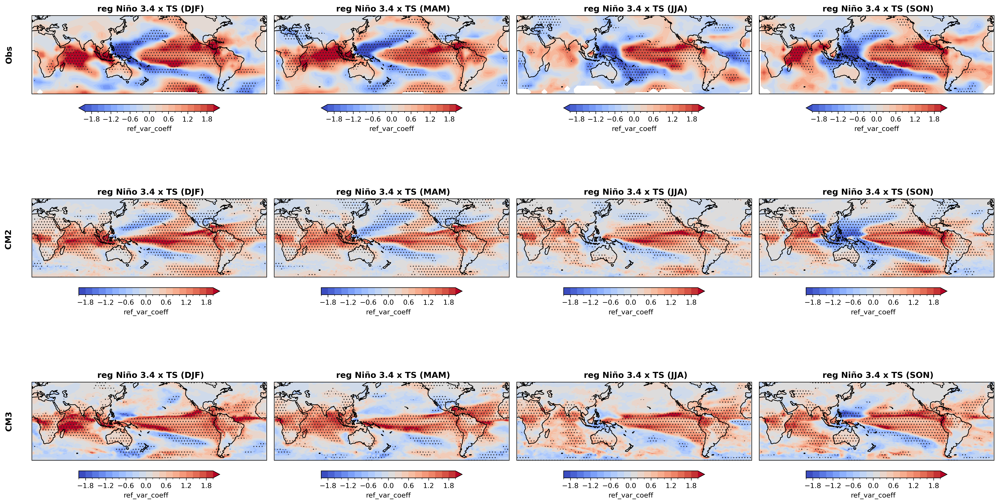

In [25]:
data_list = [coeff_obs_nino34_ts['DJF'], coeff_obs_nino34_ts['MAM'], 
             coeff_obs_nino34_ts['JJA'], coeff_obs_nino34_ts['SON'],
             coeff_cm2_nino34_ts['DJF'], coeff_cm2_nino34_ts['MAM'], 
             coeff_cm2_nino34_ts['JJA'], coeff_cm2_nino34_ts['SON'],
             coeff_cm3_nino34_ts['DJF'], coeff_cm3_nino34_ts['MAM'], 
             coeff_cm3_nino34_ts['JJA'], coeff_cm3_nino34_ts['SON'],             
            ]
pvalue_list = [pvalues_obs_nino34_ts['DJF'].where(pvalues_obs_nino34_ts['DJF']<0.05), 
               pvalues_obs_nino34_ts['MAM'].where(pvalues_obs_nino34_ts['MAM']<0.05), 
               pvalues_obs_nino34_ts['JJA'].where(pvalues_obs_nino34_ts['JJA']<0.05),
               pvalues_obs_nino34_ts['SON'].where(pvalues_obs_nino34_ts['SON']<0.05),
               pvalues_cm2_nino34_ts['DJF'].where(pvalues_cm2_nino34_ts['DJF']<0.05), 
               pvalues_cm2_nino34_ts['MAM'].where(pvalues_cm2_nino34_ts['MAM']<0.05), 
               pvalues_cm2_nino34_ts['JJA'].where(pvalues_cm2_nino34_ts['JJA']<0.05),
               pvalues_cm2_nino34_ts['SON'].where(pvalues_cm2_nino34_ts['SON']<0.05),
               pvalues_cm3_nino34_ts['DJF'].where(pvalues_cm3_nino34_ts['DJF']<0.05), 
               pvalues_cm3_nino34_ts['MAM'].where(pvalues_cm3_nino34_ts['MAM']<0.05), 
               pvalues_cm3_nino34_ts['JJA'].where(pvalues_cm3_nino34_ts['JJA']<0.05),
               pvalues_cm3_nino34_ts['SON'].where(pvalues_cm3_nino34_ts['SON']<0.05),
               ]


seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  # Style of hatching for significant areas

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 12), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-2.0, 2.0, 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    sig = ax.contourf(data.lon, data.lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()
    ax.set_extent([0,359,-60,60])

    ax.set_title(f" reg Niño 3.4 x TS ({seasons[i%4]})", fontsize=12, fontweight='bold')

model_labels=['Obs','CM2 ','CM3']
for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    ...
    if i % 4 == 0:  # first column
        ax.text(-0.08, 0.5, model_labels[i // 4],
                va='center', ha='right', rotation='vertical',
                transform=ax.transAxes, fontsize=12, fontweight='bold')    

plt.tight_layout()
plt.savefig(plotfolder+"cm3_n34_ts_regression.png", bbox_inches="tight", dpi=500)
#plt.savefig("/g/data/eg3/zg0866/plots/ACCESS_eval/red-run/esm16-red_nino34_ts_regression.png", bbox_inches="tight", dpi=500)

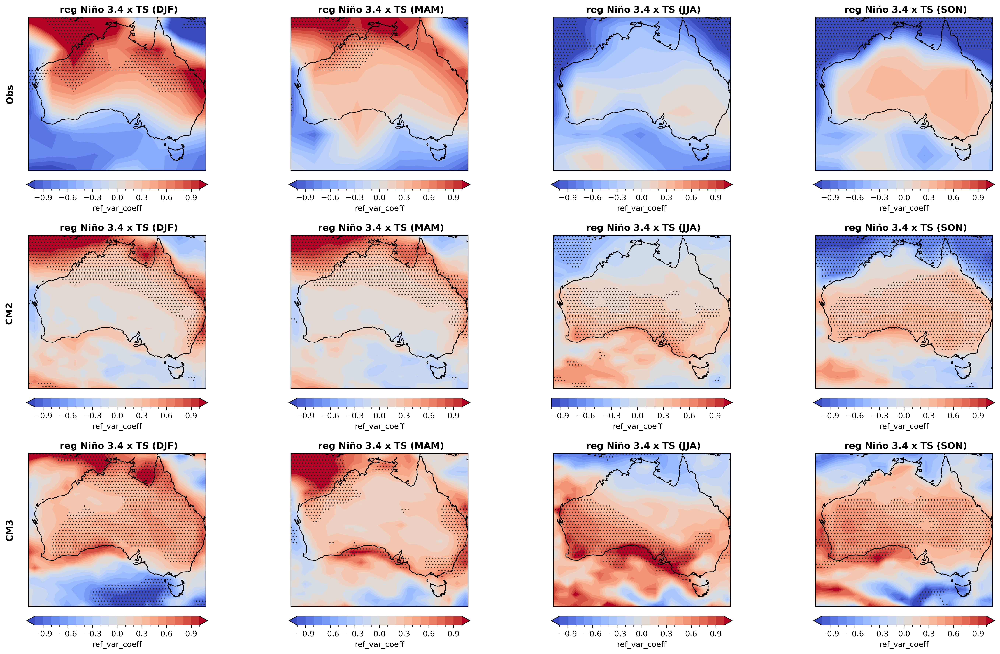

In [26]:
data_list = [coeff_obs_nino34_ts['DJF'], coeff_obs_nino34_ts['MAM'], 
             coeff_obs_nino34_ts['JJA'], coeff_obs_nino34_ts['SON'],
             coeff_cm2_nino34_ts['DJF'], coeff_cm2_nino34_ts['MAM'], 
             coeff_cm2_nino34_ts['JJA'], coeff_cm2_nino34_ts['SON'],
             coeff_cm3_nino34_ts['DJF'], coeff_cm3_nino34_ts['MAM'], 
             coeff_cm3_nino34_ts['JJA'], coeff_cm3_nino34_ts['SON'],             
            ]
pvalue_list = [pvalues_obs_nino34_ts['DJF'].where(pvalues_obs_nino34_ts['DJF']<0.05), 
               pvalues_obs_nino34_ts['MAM'].where(pvalues_obs_nino34_ts['MAM']<0.05), 
               pvalues_obs_nino34_ts['JJA'].where(pvalues_obs_nino34_ts['JJA']<0.05),
               pvalues_obs_nino34_ts['SON'].where(pvalues_obs_nino34_ts['SON']<0.05),
               pvalues_cm2_nino34_ts['DJF'].where(pvalues_cm2_nino34_ts['DJF']<0.05), 
               pvalues_cm2_nino34_ts['MAM'].where(pvalues_cm2_nino34_ts['MAM']<0.05), 
               pvalues_cm2_nino34_ts['JJA'].where(pvalues_cm2_nino34_ts['JJA']<0.05),
               pvalues_cm2_nino34_ts['SON'].where(pvalues_cm2_nino34_ts['SON']<0.05),
               pvalues_cm3_nino34_ts['DJF'].where(pvalues_cm3_nino34_ts['DJF']<0.05), 
               pvalues_cm3_nino34_ts['MAM'].where(pvalues_cm3_nino34_ts['MAM']<0.05), 
               pvalues_cm3_nino34_ts['JJA'].where(pvalues_cm3_nino34_ts['JJA']<0.05),
               pvalues_cm3_nino34_ts['SON'].where(pvalues_cm3_nino34_ts['SON']<0.05),
               ]


seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  # Style of hatching for significant areas

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 12), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-1.0, 1.0, 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    sig = ax.contourf(data.lon, data.lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()
    ax.set_extent([112,153.5,-44,-10])

    ax.set_title(f" reg Niño 3.4 x TS ({seasons[i%4]})", fontsize=12, fontweight='bold')
model_labels=['Obs','CM2 ','CM3']
for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    ...
    if i % 4 == 0:  # first column
        ax.text(-0.08, 0.5, model_labels[i // 4],
                va='center', ha='right', rotation='vertical',
                transform=ax.transAxes, fontsize=12, fontweight='bold')    

plt.tight_layout()
plt.savefig(plotfolder+"cm3_n34_ts_regression_aus.png", bbox_inches="tight", dpi=500)

#plt.savefig("/g/data/eg3/zg0866/plots/ACCESS_eval/red-run/esm16-red_nino34_ts_regression.png", bbox_inches="tight", dpi=500)

# Regression plots of DMI and TS (global, then zoomed in to Aus)

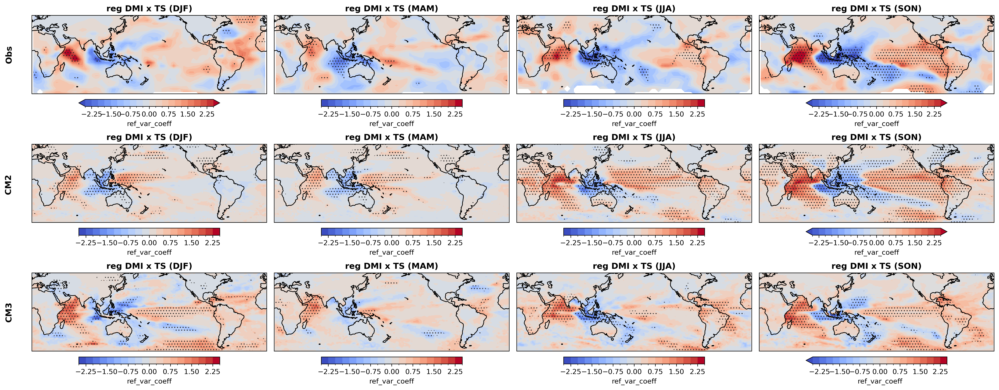

In [27]:
data_list = [coeff_obs_dmi_ts['DJF'], coeff_obs_dmi_ts['MAM'], 
             coeff_obs_dmi_ts['JJA'], coeff_obs_dmi_ts['SON'],
             coeff_cm2_dmi_ts['DJF'], coeff_cm2_dmi_ts['MAM'], 
             coeff_cm2_dmi_ts['JJA'], coeff_cm2_dmi_ts['SON'],
             coeff_cm3_dmi_ts['DJF'], coeff_cm3_dmi_ts['MAM'], 
             coeff_cm3_dmi_ts['JJA'], coeff_cm3_dmi_ts['SON'],             
            ]
pvalue_list = [pvalues_obs_dmi_ts['DJF'].where(pvalues_obs_dmi_ts['DJF']<0.05), 
               pvalues_obs_dmi_ts['MAM'].where(pvalues_obs_dmi_ts['MAM']<0.05), 
               pvalues_obs_dmi_ts['JJA'].where(pvalues_obs_dmi_ts['JJA']<0.05),
               pvalues_obs_dmi_ts['SON'].where(pvalues_obs_dmi_ts['SON']<0.05),
               pvalues_cm2_dmi_ts['DJF'].where(pvalues_cm2_dmi_ts['DJF']<0.05), 
               pvalues_cm2_dmi_ts['MAM'].where(pvalues_cm2_dmi_ts['MAM']<0.05), 
               pvalues_cm2_dmi_ts['JJA'].where(pvalues_cm2_dmi_ts['JJA']<0.05),
               pvalues_cm2_dmi_ts['SON'].where(pvalues_cm2_dmi_ts['SON']<0.05),
               pvalues_cm3_dmi_ts['DJF'].where(pvalues_cm3_dmi_ts['DJF']<0.05), 
               pvalues_cm3_dmi_ts['MAM'].where(pvalues_cm3_dmi_ts['MAM']<0.05), 
               pvalues_cm3_dmi_ts['JJA'].where(pvalues_cm3_dmi_ts['JJA']<0.05),
               pvalues_cm3_dmi_ts['SON'].where(pvalues_cm3_dmi_ts['SON']<0.05),
               ]

seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...'] 

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 8), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-2.5, 2.5, 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    sig = ax.contourf(data.lon, data.lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()
    ax.set_extent([0,359,-60,60])

    ax.set_title(f"reg DMI x TS ({seasons[i%4]})", fontsize=12, fontweight='bold')
    
model_labels=['Obs','CM2 ','CM3']
for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    ...
    if i % 4 == 0:  # first column
        ax.text(-0.08, 0.5, model_labels[i // 4],
                va='center', ha='right', rotation='vertical',
                transform=ax.transAxes, fontsize=12, fontweight='bold')    

plt.tight_layout()
plt.savefig(plotfolder+"cm3_dmi_ts_regression.png", bbox_inches="tight", dpi=500)

#plt.savefig("/g/data/eg3/zg0866/plots/ACCESS_eval/red-run/esm16-red_dmi_ts_regression.png", bbox_inches="tight", dpi=750)

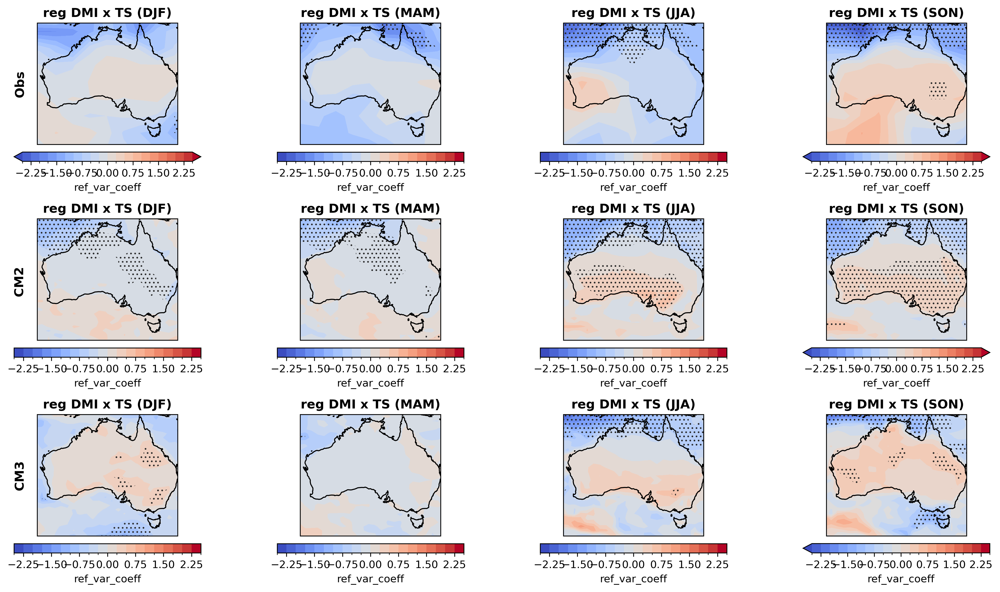

In [28]:
data_list = [coeff_obs_dmi_ts['DJF'], coeff_obs_dmi_ts['MAM'], 
             coeff_obs_dmi_ts['JJA'], coeff_obs_dmi_ts['SON'],
             coeff_cm2_dmi_ts['DJF'], coeff_cm2_dmi_ts['MAM'], 
             coeff_cm2_dmi_ts['JJA'], coeff_cm2_dmi_ts['SON'],
             coeff_cm3_dmi_ts['DJF'], coeff_cm3_dmi_ts['MAM'], 
             coeff_cm3_dmi_ts['JJA'], coeff_cm3_dmi_ts['SON'],             
            ]
pvalue_list = [pvalues_obs_dmi_ts['DJF'].where(pvalues_obs_dmi_ts['DJF']<0.05), 
               pvalues_obs_dmi_ts['MAM'].where(pvalues_obs_dmi_ts['MAM']<0.05), 
               pvalues_obs_dmi_ts['JJA'].where(pvalues_obs_dmi_ts['JJA']<0.05),
               pvalues_obs_dmi_ts['SON'].where(pvalues_obs_dmi_ts['SON']<0.05),
               pvalues_cm2_dmi_ts['DJF'].where(pvalues_cm2_dmi_ts['DJF']<0.05), 
               pvalues_cm2_dmi_ts['MAM'].where(pvalues_cm2_dmi_ts['MAM']<0.05), 
               pvalues_cm2_dmi_ts['JJA'].where(pvalues_cm2_dmi_ts['JJA']<0.05),
               pvalues_cm2_dmi_ts['SON'].where(pvalues_cm2_dmi_ts['SON']<0.05),
               pvalues_cm3_dmi_ts['DJF'].where(pvalues_cm3_dmi_ts['DJF']<0.05), 
               pvalues_cm3_dmi_ts['MAM'].where(pvalues_cm3_dmi_ts['MAM']<0.05), 
               pvalues_cm3_dmi_ts['JJA'].where(pvalues_cm3_dmi_ts['JJA']<0.05),
               pvalues_cm3_dmi_ts['SON'].where(pvalues_cm3_dmi_ts['SON']<0.05),
               ]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...'] 

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(15, 8), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-2.5, 2.5, 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    sig = ax.contourf(data.lon, data.lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()
    ax.set_extent([112,153.5,-44,-10])

    ax.set_title(f"reg DMI x TS ({seasons[i%4]})", fontsize=12, fontweight='bold')
model_labels=['Obs','CM2 ','CM3']
for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    ...
    if i % 4 == 0:  # first column
        ax.text(-0.08, 0.5, model_labels[i // 4],
                va='center', ha='right', rotation='vertical',
                transform=ax.transAxes, fontsize=12, fontweight='bold')    

plt.tight_layout()
plt.savefig(plotfolder+"cm3_dmi_ts_regression_aus.png", bbox_inches="tight", dpi=500)

#plt.savefig("/g/data/eg3/zg0866/plots/ACCESS_eval/red-run/esm16-red_dmi_ts_regression.png", bbox_inches="tight", dpi=750)

In [29]:

#read in obs and cm2 output for precip

obs = xr.open_dataset("/g/data/ct11/access-nri/replicas/esmvaltool/obsdata-v2/Tier2/GPCP-SG/OBS_GPCP-SG_atmos_2.3_Amon_pr_197901-202304.nc",decode_times=True).pr
obs_pr = obs.sel(time=slice('1980','2014'))
obs_pr = convert_units(obs_pr)


# cm2_dir = "/g/data/fs38/publications/CMIP6/CMIP/CSIRO/ACCESS-ESM1-5//r1i1p1f1/Amon/"
# cm2_pr = convert_units(xr.open_mfdataset(cm2_dir+"pr/gn/latest/pr_Amon_ACCESS-ESM1-5__r1i1p1f1_gn_*.nc",concat_dim="time",combine="nested").pr.isel(time=slice(-2400, None))).chunk({'time': -1}).chunk({'lon':96})

In [30]:

cm3_pr_monanom = calcMonAnom(cm3_pr)

cm2_pr_monanom = calcMonAnom(cm2_pr)
obs_pr_monanom = calcMonAnom(obs_pr)

cm3_pr_monanom_dt = detrend_monthly(cm3_pr_monanom, deg=1)

cm2_pr_monanom_dt = detrend_monthly(cm2_pr_monanom, deg=1)
obs_pr_monanom_dt = detrend_monthly(obs_pr_monanom, deg=1)

In [31]:
cm3_pr_seasons = get_seasonal_means(cm3_pr_monanom_dt, ['DJF', 'MAM', 'JJA', 'SON'])

cm2_pr_seasons = get_seasonal_means(cm2_pr_monanom_dt, ['DJF', 'MAM', 'JJA', 'SON'])
obs_pr_seasons = get_seasonal_means(obs_pr_monanom_dt, ['DJF', 'MAM', 'JJA', 'SON'])

In [32]:
# print(cm2_pr_seasons)
# print(cm2_nino34_seasons)

In [33]:
coeff_cm3_nino34_pr, pvalues_cm3_nino34_pr = calculate_regression(cm3_pr_seasons, cm3_nino34_seasons)
coeff_cm2_nino34_pr, pvalues_cm2_nino34_pr = calculate_regression(cm2_pr_seasons, cm2_nino34_seasons)
coeff_obs_nino34_pr, pvalues_obs_nino34_pr = calculate_regression(obs_pr_seasons, obs_nino34_seasons)

In [34]:
corr_cm3_nino34_pr, cpvalues_cm3_nino34_pr = calculate_correlation(cm3_pr_seasons, cm3_nino34_seasons)
corr_cm2_nino34_pr, cpvalues_cm2_nino34_pr = calculate_correlation(cm2_pr_seasons, cm2_nino34_seasons)
corr_obs_nino34_pr, cpvalues_obs_nino34_pr = calculate_correlation(obs_pr_seasons, obs_nino34_seasons)

In [35]:
#coeff_cm2_nino34_pr, pvalues_cm2_nino34_pr = calculate_regression(cm2_pr_seasons, cm2_nino34_seasons)


In [36]:
coeff_cm3_dmi_pr, pvalues_cm3_dmi_pr = calculate_regression(cm3_pr_seasons, cm3_dmi_seasons)
coeff_cm2_dmi_pr, pvalues_cm2_dmi_pr = calculate_regression(cm2_pr_seasons, cm2_dmi_seasons)
coeff_obs_dmi_pr, pvalues_obs_dmi_pr = calculate_regression(obs_pr_seasons, obs_dmi_seasons)


In [37]:


corr_cm3_dmi_pr, cpvalues_cm3_dmi_pr = calculate_correlation(cm3_pr_seasons, cm3_dmi_seasons)
corr_cm2_dmi_pr, cpvalues_cm2_dmi_pr = calculate_correlation(cm2_pr_seasons, cm2_dmi_seasons)
corr_obs_dmi_pr, cpvalues_obs_dmi_pr = calculate_correlation(obs_pr_seasons, obs_dmi_seasons)

In [38]:
#print(coeff_obs_nino34_pr['DJF'])

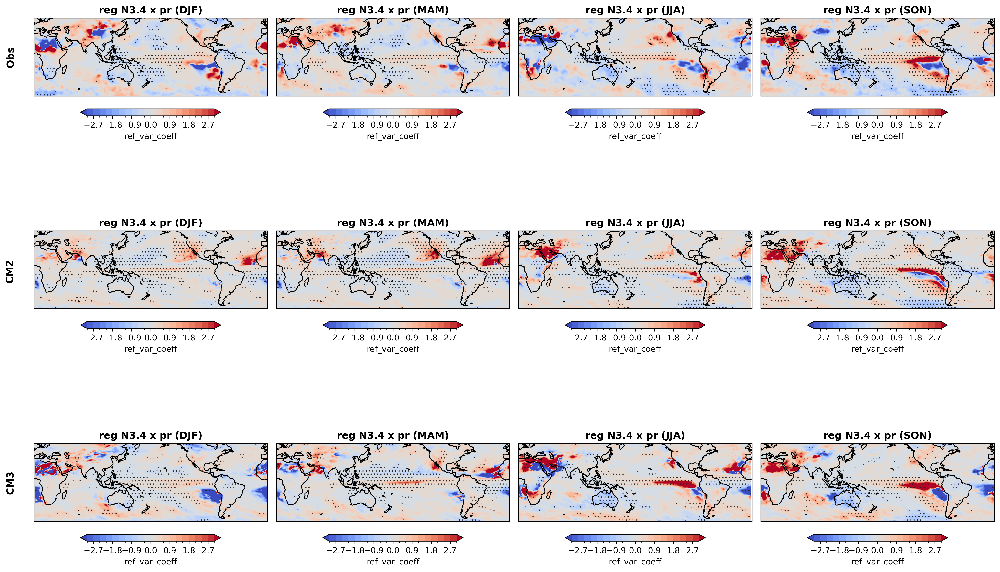

In [39]:
data_list = [coeff_obs_nino34_pr['DJF'], coeff_obs_nino34_pr['MAM'], 
             coeff_obs_nino34_pr['JJA'], coeff_obs_nino34_pr['SON'],
             coeff_cm2_nino34_pr['DJF'], coeff_cm2_nino34_pr['MAM'], 
             coeff_cm2_nino34_pr['JJA'], coeff_cm2_nino34_pr['SON'],
             coeff_cm3_nino34_pr['DJF'], coeff_cm3_nino34_pr['MAM'], 
             coeff_cm3_nino34_pr['JJA'], coeff_cm3_nino34_pr['SON'],             
            ]
pvalue_list = [pvalues_obs_nino34_pr['DJF'].where(pvalues_obs_nino34_pr['DJF']<0.05), 
               pvalues_obs_nino34_pr['MAM'].where(pvalues_obs_nino34_pr['MAM']<0.05), 
               pvalues_obs_nino34_pr['JJA'].where(pvalues_obs_nino34_pr['JJA']<0.05),
               pvalues_obs_nino34_pr['SON'].where(pvalues_obs_nino34_pr['SON']<0.05),
               pvalues_cm2_nino34_pr['DJF'].where(pvalues_cm2_nino34_pr['DJF']<0.05), 
               pvalues_cm2_nino34_pr['MAM'].where(pvalues_cm2_nino34_pr['MAM']<0.05), 
               pvalues_cm2_nino34_pr['JJA'].where(pvalues_cm2_nino34_pr['JJA']<0.05),
               pvalues_cm2_nino34_pr['SON'].where(pvalues_cm2_nino34_pr['SON']<0.05),
               pvalues_cm3_nino34_pr['DJF'].where(pvalues_cm3_nino34_pr['DJF']<0.05), 
               pvalues_cm3_nino34_pr['MAM'].where(pvalues_cm3_nino34_pr['MAM']<0.05), 
               pvalues_cm3_nino34_pr['JJA'].where(pvalues_cm3_nino34_pr['JJA']<0.05),
               pvalues_cm3_nino34_pr['SON'].where(pvalues_cm3_nino34_pr['SON']<0.05),
               ]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(17, 12), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-3., 3., 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    lon = data.coords.get('lon', data.coords.get('longitude'))
    lat = data.coords.get('lat', data.coords.get('latitude'))

    sig = ax.contourf(lon, lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()

    ax.set_extent([0,359,-60,60])

    ax.set_title(f"reg N3.4 x pr ({seasons[i%4]})", fontsize=12, fontweight='bold')
model_labels=['Obs','CM2 ','CM3']
for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    ...
    if i % 4 == 0:  # first column
        ax.text(-0.08, 0.5, model_labels[i // 4],
                va='center', ha='right', rotation='vertical',
                transform=ax.transAxes, fontsize=12, fontweight='bold')    

plt.tight_layout()
plt.savefig(plotfolder+"cm3_n34_pr_regression.png", bbox_inches="tight", dpi=500)

#plt.savefig("/g/data/eg3/zg0866/plots/ACCESS_eval/red-run/esm16-red_nino34_pr_regression.png", bbox_inches="tight", dpi=500)#

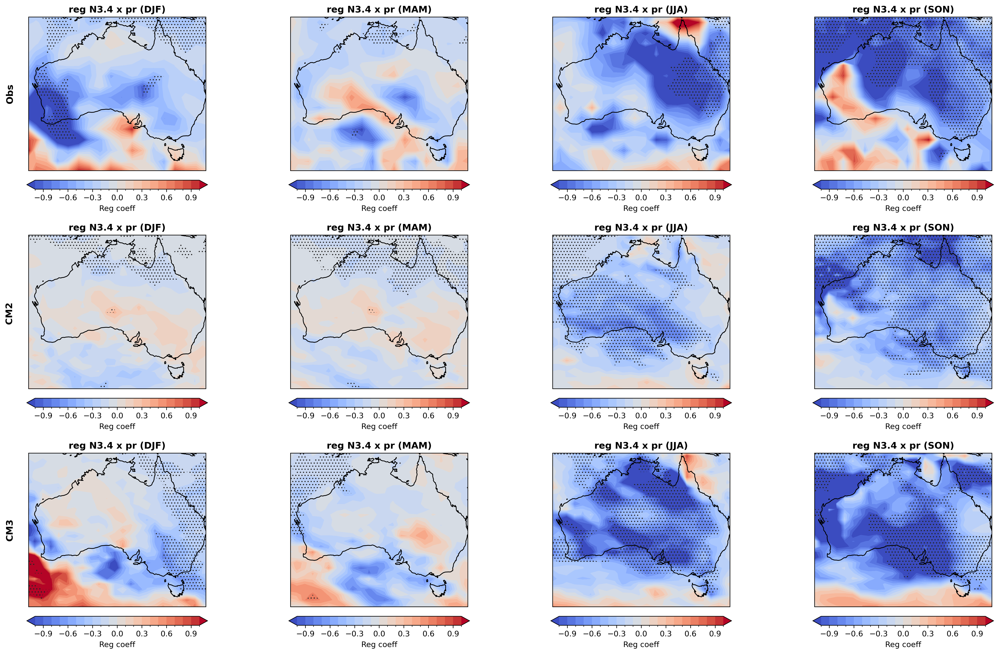

In [40]:
data_list = [coeff_obs_nino34_pr['DJF'], coeff_obs_nino34_pr['MAM'], 
             coeff_obs_nino34_pr['JJA'], coeff_obs_nino34_pr['SON'],
             coeff_cm2_nino34_pr['DJF'], coeff_cm2_nino34_pr['MAM'], 
             coeff_cm2_nino34_pr['JJA'], coeff_cm2_nino34_pr['SON'],
             coeff_cm3_nino34_pr['DJF'], coeff_cm3_nino34_pr['MAM'], 
             coeff_cm3_nino34_pr['JJA'], coeff_cm3_nino34_pr['SON'],             
            ]
pvalue_list = [pvalues_obs_nino34_pr['DJF'].where(pvalues_obs_nino34_pr['DJF']<0.05), 
               pvalues_obs_nino34_pr['MAM'].where(pvalues_obs_nino34_pr['MAM']<0.05), 
               pvalues_obs_nino34_pr['JJA'].where(pvalues_obs_nino34_pr['JJA']<0.05),
               pvalues_obs_nino34_pr['SON'].where(pvalues_obs_nino34_pr['SON']<0.05),
               pvalues_cm2_nino34_pr['DJF'].where(pvalues_cm2_nino34_pr['DJF']<0.05), 
               pvalues_cm2_nino34_pr['MAM'].where(pvalues_cm2_nino34_pr['MAM']<0.05), 
               pvalues_cm2_nino34_pr['JJA'].where(pvalues_cm2_nino34_pr['JJA']<0.05),
               pvalues_cm2_nino34_pr['SON'].where(pvalues_cm2_nino34_pr['SON']<0.05),
               pvalues_cm3_nino34_pr['DJF'].where(pvalues_cm3_nino34_pr['DJF']<0.05), 
               pvalues_cm3_nino34_pr['MAM'].where(pvalues_cm3_nino34_pr['MAM']<0.05), 
               pvalues_cm3_nino34_pr['JJA'].where(pvalues_cm3_nino34_pr['JJA']<0.05),
               pvalues_cm3_nino34_pr['SON'].where(pvalues_cm3_nino34_pr['SON']<0.05),
               ]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 12), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-1., 1., 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both','label':'Reg coeff'}
    )
    
    lon = data.coords.get('lon', data.coords.get('longitude'))
    lat = data.coords.get('lat', data.coords.get('latitude'))

    sig = ax.contourf(lon, lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()

    ax.set_extent([112,153.5,-44,-10])

    ax.set_title(f"reg N3.4 x pr ({seasons[i%4]})", fontsize=12, fontweight='bold')

model_labels=['Obs','CM2 ','CM3']
for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    ...
    if i % 4 == 0:  # first column
        ax.text(-0.08, 0.5, model_labels[i // 4],
                va='center', ha='right', rotation='vertical',
                transform=ax.transAxes, fontsize=12, fontweight='bold')    

plt.tight_layout()
plt.savefig(plotfolder+"cm3_n34_pr_regression_aus.png", bbox_inches="tight", dpi=500)


0
1
2
3
4
5
6
7
8
9
10
11


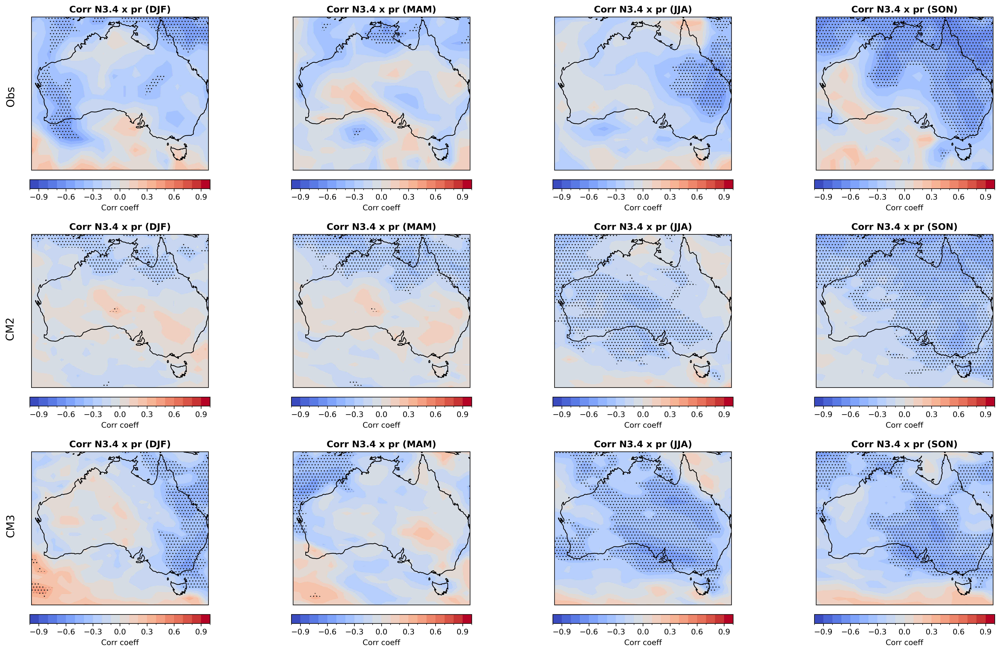

In [41]:
data_list = [corr_obs_nino34_pr['DJF'], corr_obs_nino34_pr['MAM'], 
             corr_obs_nino34_pr['JJA'], corr_obs_nino34_pr['SON'],
             corr_cm2_nino34_pr['DJF'], corr_cm2_nino34_pr['MAM'], 
             corr_cm2_nino34_pr['JJA'], corr_cm2_nino34_pr['SON'],
             corr_cm3_nino34_pr['DJF'], corr_cm3_nino34_pr['MAM'], 
             corr_cm3_nino34_pr['JJA'], corr_cm3_nino34_pr['SON'],             
            ]
pvalue_list = [cpvalues_obs_nino34_pr['DJF'].where(cpvalues_obs_nino34_pr['DJF']<0.05), 
               cpvalues_obs_nino34_pr['MAM'].where(cpvalues_obs_nino34_pr['MAM']<0.05), 
               cpvalues_obs_nino34_pr['JJA'].where(cpvalues_obs_nino34_pr['JJA']<0.05),
               cpvalues_obs_nino34_pr['SON'].where(cpvalues_obs_nino34_pr['SON']<0.05),
               cpvalues_cm2_nino34_pr['DJF'].where(cpvalues_cm2_nino34_pr['DJF']<0.05), 
               cpvalues_cm2_nino34_pr['MAM'].where(cpvalues_cm2_nino34_pr['MAM']<0.05), 
               cpvalues_cm2_nino34_pr['JJA'].where(cpvalues_cm2_nino34_pr['JJA']<0.05),
               cpvalues_cm2_nino34_pr['SON'].where(cpvalues_cm2_nino34_pr['SON']<0.05),
               cpvalues_cm3_nino34_pr['DJF'].where(cpvalues_cm3_nino34_pr['DJF']<0.05), 
               cpvalues_cm3_nino34_pr['MAM'].where(cpvalues_cm3_nino34_pr['MAM']<0.05), 
               cpvalues_cm3_nino34_pr['JJA'].where(cpvalues_cm3_nino34_pr['JJA']<0.05),
               cpvalues_cm3_nino34_pr['SON'].where(cpvalues_cm3_nino34_pr['SON']<0.05),
               ]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 12), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-1., 1., 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both','label':'Corr coeff'}
    )
    
    lon = data.coords.get('lon', data.coords.get('longitude'))
    lat = data.coords.get('lat', data.coords.get('latitude'))

    sig = ax.contourf(lon, lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()

    ax.set_extent([112,153.5,-44,-10])
    print(i)
    if (i==0):
        ax.set_ylabel('Obs')
    if (i==4):
        ax.set_ylabel('CM2 ')
    if (i==8):
        ax.set_ylabel('CM3')

    ax.set_title(f"Corr N3.4 x pr ({seasons[i%4]})", fontsize=12, fontweight='bold')

fig.text(0.04, 0.85, "Obs", va="center", rotation="vertical", fontsize=14)
fig.text(0.04, 0.50, "CM2 ", va="center", rotation="vertical", fontsize=14)
fig.text(0.04, 0.2, "CM3", va="center", rotation="vertical", fontsize=14)

plt.tight_layout()
plt.savefig(plotfolder+"cm3_n34_pr_correlation.png", bbox_inches="tight", dpi=500)


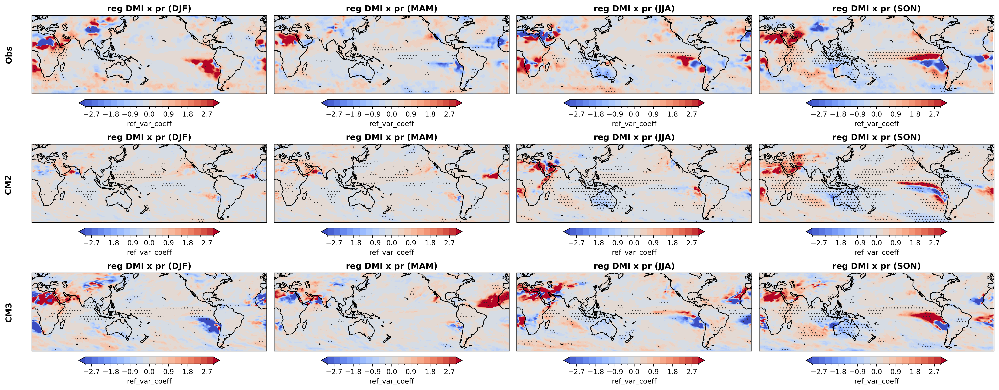

In [42]:
data_list = [coeff_obs_dmi_pr['DJF'], coeff_obs_dmi_pr['MAM'], 
             coeff_obs_dmi_pr['JJA'], coeff_obs_dmi_pr['SON'],
             coeff_cm2_dmi_pr['DJF'], coeff_cm2_dmi_pr['MAM'], 
             coeff_cm2_dmi_pr['JJA'], coeff_cm2_dmi_pr['SON'],
             coeff_cm3_dmi_pr['DJF'], coeff_cm3_dmi_pr['MAM'], 
             coeff_cm3_dmi_pr['JJA'], coeff_cm3_dmi_pr['SON'],             
            ]
pvalue_list = [pvalues_obs_dmi_pr['DJF'].where(pvalues_obs_dmi_pr['DJF']<0.05), 
               pvalues_obs_dmi_pr['MAM'].where(pvalues_obs_dmi_pr['MAM']<0.05), 
               pvalues_obs_dmi_pr['JJA'].where(pvalues_obs_dmi_pr['JJA']<0.05),
               pvalues_obs_dmi_pr['SON'].where(pvalues_obs_dmi_pr['SON']<0.05),
               pvalues_cm2_dmi_pr['DJF'].where(pvalues_cm2_dmi_pr['DJF']<0.05), 
               pvalues_cm2_dmi_pr['MAM'].where(pvalues_cm2_dmi_pr['MAM']<0.05), 
               pvalues_cm2_dmi_pr['JJA'].where(pvalues_cm2_dmi_pr['JJA']<0.05),
               pvalues_cm2_dmi_pr['SON'].where(pvalues_cm2_dmi_pr['SON']<0.05),
               pvalues_cm3_dmi_pr['DJF'].where(pvalues_cm3_dmi_pr['DJF']<0.05), 
               pvalues_cm3_dmi_pr['MAM'].where(pvalues_cm3_dmi_pr['MAM']<0.05), 
               pvalues_cm3_dmi_pr['JJA'].where(pvalues_cm3_dmi_pr['JJA']<0.05),
               pvalues_cm3_dmi_pr['SON'].where(pvalues_cm3_dmi_pr['SON']<0.05),
               ]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 8), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-3., 3., 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    lon = data.coords.get('lon', data.coords.get('longitude'))
    lat = data.coords.get('lat', data.coords.get('latitude'))

    sig = ax.contourf(lon, lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()

    ax.set_extent([0,359,-60,60])

    ax.set_title(f"reg DMI x pr ({seasons[i%4]})", fontsize=12, fontweight='bold')
model_labels=['Obs','CM2 ','CM3']
for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    ...
    if i % 4 == 0:  # first column
        ax.text(-0.08, 0.5, model_labels[i // 4],
                va='center', ha='right', rotation='vertical',
                transform=ax.transAxes, fontsize=12, fontweight='bold')    

plt.tight_layout()
plt.savefig(plotfolder+"cm3_dmi_pr_regression.png", bbox_inches="tight", dpi=500)

#plt.savefig("/g/data/eg3/zg0866/plots/ACCESS_eval/red-run/esm16-red_dmi_pr_regression.png", bbox_inches="tight", dpi=500)#

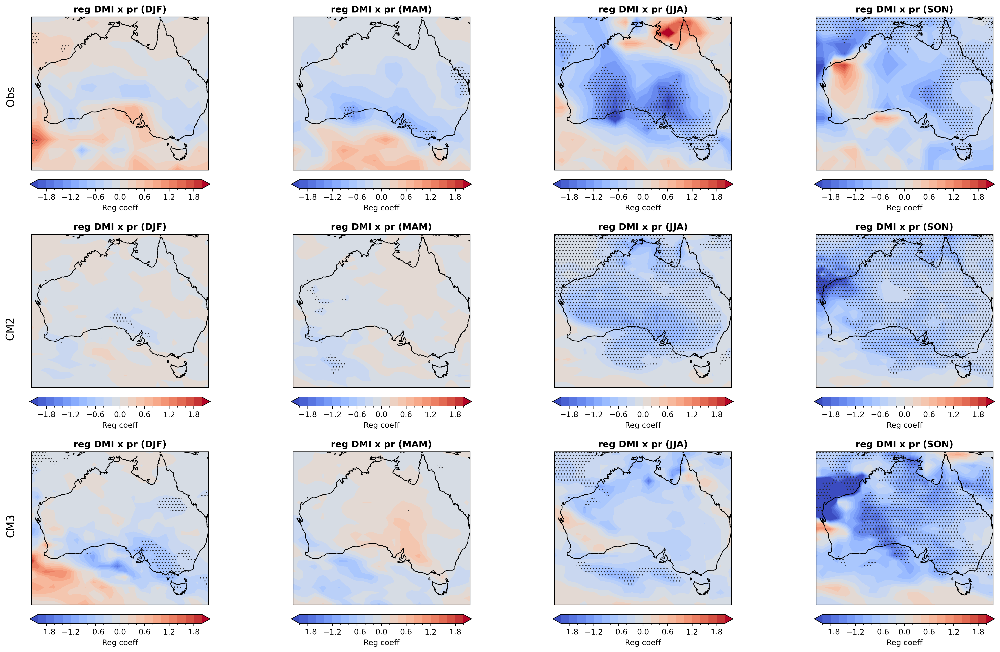

In [43]:
data_list = [coeff_obs_dmi_pr['DJF'], coeff_obs_dmi_pr['MAM'], 
             coeff_obs_dmi_pr['JJA'], coeff_obs_dmi_pr['SON'],
             coeff_cm2_dmi_pr['DJF'], coeff_cm2_dmi_pr['MAM'], 
             coeff_cm2_dmi_pr['JJA'], coeff_cm2_dmi_pr['SON'],
             coeff_cm3_dmi_pr['DJF'], coeff_cm3_dmi_pr['MAM'], 
             coeff_cm3_dmi_pr['JJA'], coeff_cm3_dmi_pr['SON'],             
            ]
pvalue_list = [pvalues_obs_dmi_pr['DJF'].where(pvalues_obs_dmi_pr['DJF']<0.05), 
               pvalues_obs_dmi_pr['MAM'].where(pvalues_obs_dmi_pr['MAM']<0.05), 
               pvalues_obs_dmi_pr['JJA'].where(pvalues_obs_dmi_pr['JJA']<0.05),
               pvalues_obs_dmi_pr['SON'].where(pvalues_obs_dmi_pr['SON']<0.05),
               pvalues_cm2_dmi_pr['DJF'].where(pvalues_cm2_dmi_pr['DJF']<0.05), 
               pvalues_cm2_dmi_pr['MAM'].where(pvalues_cm2_dmi_pr['MAM']<0.05), 
               pvalues_cm2_dmi_pr['JJA'].where(pvalues_cm2_dmi_pr['JJA']<0.05),
               pvalues_cm2_dmi_pr['SON'].where(pvalues_cm2_dmi_pr['SON']<0.05),
               pvalues_cm3_dmi_pr['DJF'].where(pvalues_cm3_dmi_pr['DJF']<0.05), 
               pvalues_cm3_dmi_pr['MAM'].where(pvalues_cm3_dmi_pr['MAM']<0.05), 
               pvalues_cm3_dmi_pr['JJA'].where(pvalues_cm3_dmi_pr['JJA']<0.05),
               pvalues_cm3_dmi_pr['SON'].where(pvalues_cm3_dmi_pr['SON']<0.05),
               ]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 12), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-2., 2., 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both','label':'Reg coeff'}
    )

    lon = data.coords.get('lon', data.coords.get('longitude'))
    lat = data.coords.get('lat', data.coords.get('latitude'))

    sig = ax.contourf(lon, lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()

    ax.set_extent([112,153.5,-44,-10])

    ax.set_title(f"reg DMI x pr ({seasons[i%4]})", fontsize=12, fontweight='bold')
    if (i==0):
        ax.set_ylabel('Obs')
    if (i==4):
        ax.set_ylabel('CM2 ')
    if (i==8):
        ax.set_ylabel('CM3')


fig.text(0.04, 0.85, "Obs", va="center", rotation="vertical", fontsize=14)
fig.text(0.04, 0.50, "CM2 ", va="center", rotation="vertical", fontsize=14)
fig.text(0.04, 0.2, "CM3", va="center", rotation="vertical", fontsize=14)

plt.tight_layout()
plt.savefig(plotfolder+"cm3_dmi_pr_regression_aus.png", bbox_inches="tight", dpi=500)


0
1
2
3
4
5
6
7
8
9
10
11


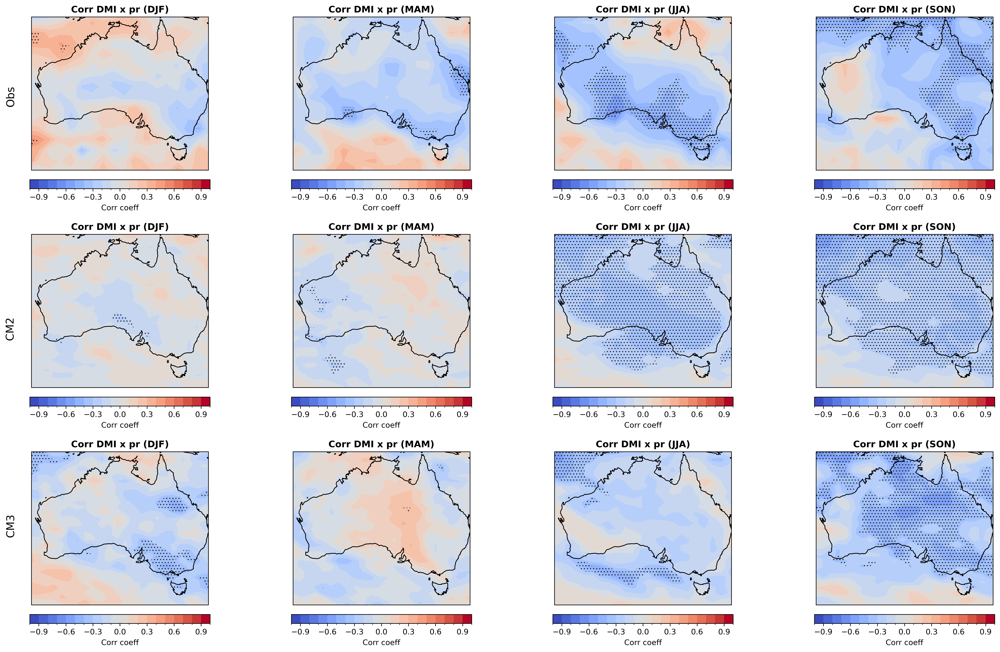

In [44]:
data_list = [corr_obs_dmi_pr['DJF'], corr_obs_dmi_pr['MAM'], 
             corr_obs_dmi_pr['JJA'], corr_obs_dmi_pr['SON'],
             corr_cm2_dmi_pr['DJF'], corr_cm2_dmi_pr['MAM'], 
             corr_cm2_dmi_pr['JJA'], corr_cm2_dmi_pr['SON'],
             corr_cm3_dmi_pr['DJF'], corr_cm3_dmi_pr['MAM'], 
             corr_cm3_dmi_pr['JJA'], corr_cm3_dmi_pr['SON'],             
            ]
pvalue_list = [cpvalues_obs_dmi_pr['DJF'].where(cpvalues_obs_dmi_pr['DJF']<0.05), 
               cpvalues_obs_dmi_pr['MAM'].where(cpvalues_obs_dmi_pr['MAM']<0.05), 
               cpvalues_obs_dmi_pr['JJA'].where(cpvalues_obs_dmi_pr['JJA']<0.05),
               cpvalues_obs_dmi_pr['SON'].where(cpvalues_obs_dmi_pr['SON']<0.05),
               cpvalues_cm2_dmi_pr['DJF'].where(cpvalues_cm2_dmi_pr['DJF']<0.05), 
               cpvalues_cm2_dmi_pr['MAM'].where(cpvalues_cm2_dmi_pr['MAM']<0.05), 
               cpvalues_cm2_dmi_pr['JJA'].where(cpvalues_cm2_dmi_pr['JJA']<0.05),
               cpvalues_cm2_dmi_pr['SON'].where(cpvalues_cm2_dmi_pr['SON']<0.05),
               cpvalues_cm3_dmi_pr['DJF'].where(cpvalues_cm3_dmi_pr['DJF']<0.05), 
               cpvalues_cm3_dmi_pr['MAM'].where(cpvalues_cm3_dmi_pr['MAM']<0.05), 
               cpvalues_cm3_dmi_pr['JJA'].where(cpvalues_cm3_dmi_pr['JJA']<0.05),
               cpvalues_cm3_dmi_pr['SON'].where(cpvalues_cm3_dmi_pr['SON']<0.05),
               ]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 12), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-1., 1., 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both','label':'Corr coeff'}
    )
    
    lon = data.coords.get('lon', data.coords.get('longitude'))
    lat = data.coords.get('lat', data.coords.get('latitude'))

    sig = ax.contourf(lon, lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()

    ax.set_extent([112,153.5,-44,-10])
    print(i)
    if (i==0):
        ax.set_ylabel('Obs')
    if (i==4):
        ax.set_ylabel('CM2 ')
    if (i==8):
        ax.set_ylabel('CM3')

    ax.set_title(f"Corr DMI x pr ({seasons[i%4]})", fontsize=12, fontweight='bold')

fig.text(0.04, 0.85, "Obs", va="center", rotation="vertical", fontsize=14)
fig.text(0.04, 0.50, "CM2 ", va="center", rotation="vertical", fontsize=14)
fig.text(0.04, 0.2, "CM3", va="center", rotation="vertical", fontsize=14)

plt.tight_layout()
plt.savefig(plotfolder+"cm3_dmi_pr_regression_aus.png", bbox_inches="tight", dpi=500)


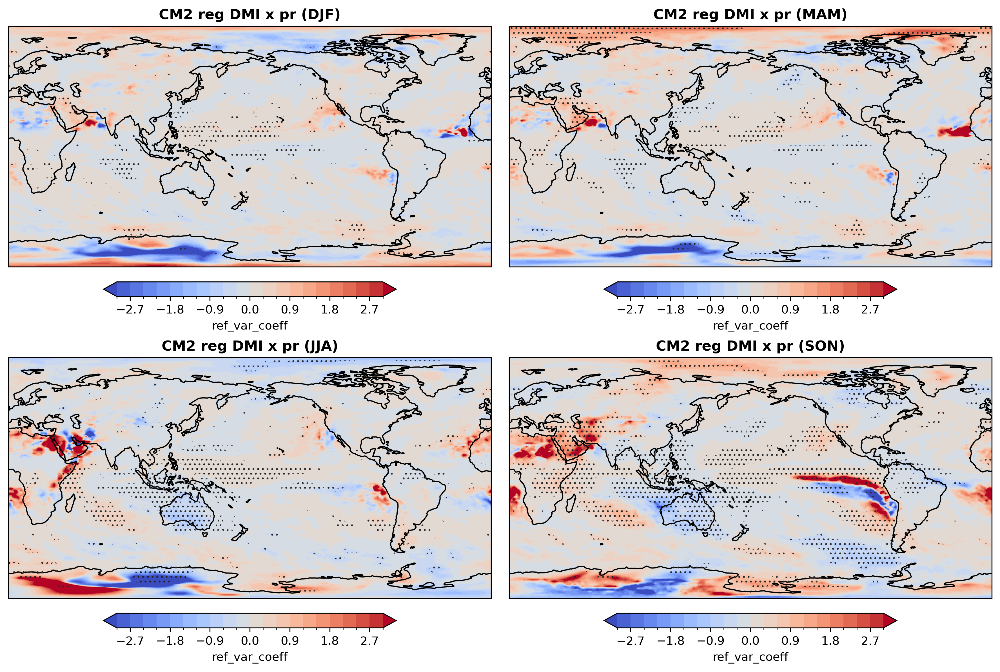

In [45]:
data_list = [coeff_cm2_dmi_pr['DJF'], coeff_cm2_dmi_pr['MAM'], 
             coeff_cm2_dmi_pr['JJA'], coeff_cm2_dmi_pr['SON'],
            ]
pvalue_list = [pvalues_cm2_dmi_pr['DJF'].where(pvalues_cm2_dmi_pr['DJF']<0.05), 
               pvalues_cm2_dmi_pr['MAM'].where(pvalues_cm2_dmi_pr['MAM']<0.05), 
               pvalues_cm2_dmi_pr['JJA'].where(pvalues_cm2_dmi_pr['JJA']<0.05),
               pvalues_cm2_dmi_pr['SON'].where(pvalues_cm2_dmi_pr['SON']<0.05)]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-3., 3., 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    sig = ax.contourf(data.lon, data.lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()
    ax.set_title(f"CM2 reg DMI x pr ({seasons[i]})", fontsize=12, fontweight='bold')

plt.tight_layout()
#
#plt.savefig("/g/data/eg3/zg0866/plots/ACCESS_eval/red-run/cm2_dmi_pr_regression.png", bbox_inches="tight", dpi=500)#

# PSL 

In [77]:
#note I can't find monthly psl in the datastore (only daily)
#so I'm just taking monthly means of the daily output for now..

cm3_psl_daily = convert_units(psl.fld_s16i222)

cm3_psl = cm3_psl_daily.resample(time="1M").mean()



In [78]:
cm2_psl_xr = xr.open_dataset("/g/data/eg3/cxc548/nesp/ACCESS_testing/atmos_fields_cm225km_001-141.nc",decode_times=True).psl
cm2_psl = convert_units(cm2_psl_xr)

In [79]:

cm3_psl_monanom = calcMonAnom(cm3_psl)
cm2_psl_monanom = calcMonAnom(cm2_psl)

cm3_psl_monanom_dt = detrend_monthly(cm3_psl_monanom, deg=1)
cm2_psl_monanom_dt = detrend_monthly(cm2_psl_monanom, deg=1)

In [80]:
cm3_psl_seasons = get_seasonal_means(cm3_psl_monanom_dt, ['DJF', 'MAM', 'JJA', 'SON'])
cm2_psl_seasons = get_seasonal_means(cm2_psl_monanom_dt, ['DJF', 'MAM', 'JJA', 'SON'])

In [81]:

coeff_cm3_nino34_psl, pvalues_cm3_nino34_psl = calculate_regression(cm3_psl_seasons, cm3_nino34_seasons)

<xarray.DataArray 'fld_s16i222' (time: 600, lat: 144, lon: 192)> Size: 66MB
dask.array<transpose, shape=(600, 144, 192), dtype=float32, chunksize=(1, 144, 192), chunktype=numpy.ndarray>
Coordinates:
  * time                (time) datetime64[ns] 5kB 1981-01-31 ... 2030-12-31
  * lat                 (lat) float64 1kB -89.38 -88.12 -86.88 ... 88.12 89.38
  * lon                 (lon) float64 2kB 0.9375 2.812 4.688 ... 357.2 359.1
    latitude_longitude  int32 4B ...
    height              float64 8B ...
    height_0            float64 8B ...
Attributes:
    units:    hPa


In [82]:
coeff_cm3_dmi_psl, pvalues_cm3_dmi_psl = calculate_regression(cm3_psl_seasons, cm3_dmi_seasons)

In [83]:
coeff_cm2_nino34_psl, pvalues_cm2_nino34_psl = calculate_regression(cm2_psl_seasons, cm2_nino34_seasons)

In [84]:
coeff_cm2_dmi_psl, pvalues_cm2_dmi_psl = calculate_regression(cm2_psl_seasons, cm2_dmi_seasons)

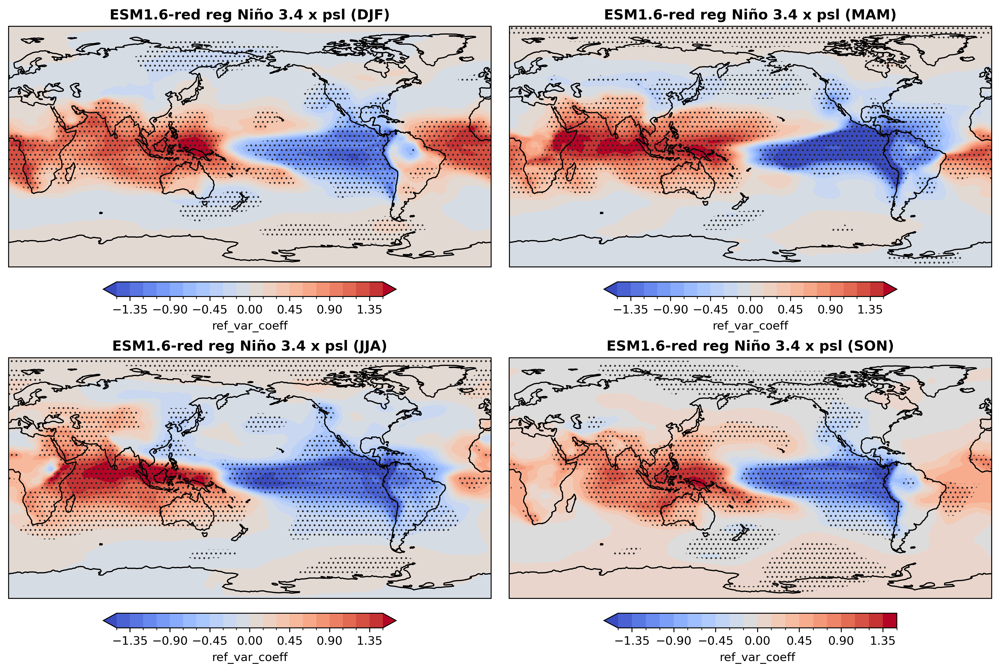

In [86]:
data_list = [coeff_cm3_nino34_psl['DJF'], coeff_cm3_nino34_psl['MAM'], coeff_cm3_nino34_psl['JJA'], coeff_cm3_nino34_psl['SON']]
pvalue_list = [pvalues_cm3_nino34_psl['DJF'].where(pvalues_cm3_nino34_psl['DJF']<0.05), 
               pvalues_cm3_nino34_psl['MAM'].where(pvalues_cm3_nino34_psl['MAM']<0.05), 
               pvalues_cm3_nino34_psl['JJA'].where(pvalues_cm3_nino34_psl['JJA']<0.05),
               pvalues_cm3_nino34_psl['SON'].where(pvalues_cm3_nino34_psl['SON']<0.05)]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-1.5, 1.5, 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    sig = ax.contourf(data.lon, data.lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()
    ax.set_title(f"ESM1.6-red reg Niño 3.4 x psl ({seasons[i]})", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(plotfolder+"cm3_n34_psl_regression.png", bbox_inches="tight", dpi=500)

#plt.savefig("/g/data/eg3/zg0866/plots/ACCESS_eval/red-run/esm16-red_nino34_psl_regression.png", bbox_inches="tight", dpi=500)#

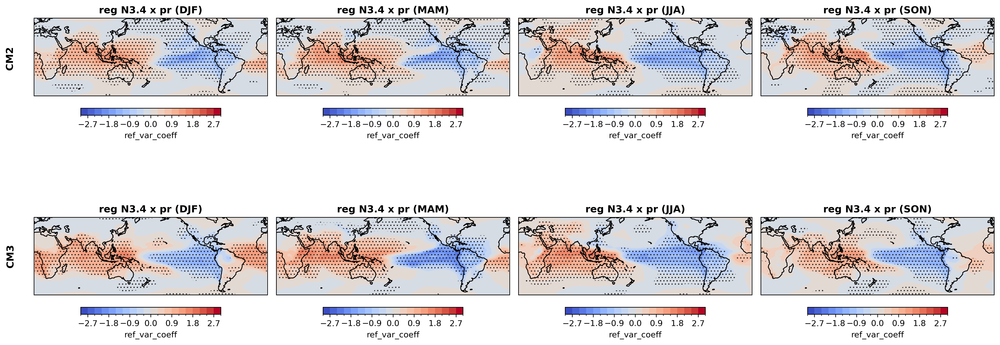

In [90]:
data_list = [coeff_cm2_nino34_psl['DJF'], coeff_cm2_nino34_psl['MAM'], 
             coeff_cm2_nino34_psl['JJA'], coeff_cm2_nino34_psl['SON'],
             coeff_cm3_nino34_psl['DJF'], coeff_cm3_nino34_psl['MAM'], 
             coeff_cm3_nino34_psl['JJA'], coeff_cm3_nino34_psl['SON'],             
            ]
pvalue_list = [pvalues_cm2_nino34_psl['DJF'].where(pvalues_cm2_nino34_psl['DJF']<0.05), 
               pvalues_cm2_nino34_psl['MAM'].where(pvalues_cm2_nino34_psl['MAM']<0.05), 
               pvalues_cm2_nino34_psl['JJA'].where(pvalues_cm2_nino34_psl['JJA']<0.05),
               pvalues_cm2_nino34_psl['SON'].where(pvalues_cm2_nino34_psl['SON']<0.05),
               pvalues_cm3_nino34_psl['DJF'].where(pvalues_cm3_nino34_psl['DJF']<0.05), 
               pvalues_cm3_nino34_psl['MAM'].where(pvalues_cm3_nino34_psl['MAM']<0.05), 
               pvalues_cm3_nino34_psl['JJA'].where(pvalues_cm3_nino34_psl['JJA']<0.05),
               pvalues_cm3_nino34_psl['SON'].where(pvalues_cm3_nino34_psl['SON']<0.05),
               ]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(17, 8), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-3., 3., 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    lon = data.coords.get('lon', data.coords.get('longitude'))
    lat = data.coords.get('lat', data.coords.get('latitude'))

    sig = ax.contourf(lon, lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()

    ax.set_extent([0,359,-60,60])

    ax.set_title(f"reg N3.4 x pr ({seasons[i%4]})", fontsize=12, fontweight='bold')
model_labels=['CM2 ','CM3']
for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    ...
    if i % 4 == 0:  # first column
        ax.text(-0.08, 0.5, model_labels[i // 4],
                va='center', ha='right', rotation='vertical',
                transform=ax.transAxes, fontsize=12, fontweight='bold')    

plt.tight_layout()
plt.savefig(plotfolder+"cm3_n34_psl_regression.png", bbox_inches="tight", dpi=500)


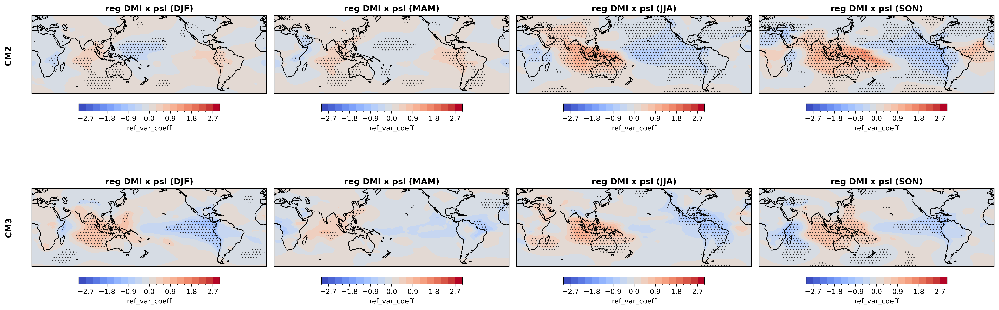

In [89]:
data_list = [coeff_cm2_dmi_psl['DJF'], coeff_cm2_dmi_psl['MAM'], 
             coeff_cm2_dmi_psl['JJA'], coeff_cm2_dmi_psl['SON'],
             coeff_cm3_dmi_psl['DJF'], coeff_cm3_dmi_psl['MAM'], 
             coeff_cm3_dmi_psl['JJA'], coeff_cm3_dmi_psl['SON'],             
            ]
pvalue_list = [pvalues_cm2_dmi_psl['DJF'].where(pvalues_cm2_dmi_psl['DJF']<0.05), 
               pvalues_cm2_dmi_psl['MAM'].where(pvalues_cm2_dmi_psl['MAM']<0.05), 
               pvalues_cm2_dmi_psl['JJA'].where(pvalues_cm2_dmi_psl['JJA']<0.05),
               pvalues_cm2_dmi_psl['SON'].where(pvalues_cm2_dmi_psl['SON']<0.05),
               pvalues_cm3_dmi_psl['DJF'].where(pvalues_cm3_dmi_psl['DJF']<0.05), 
               pvalues_cm3_dmi_psl['MAM'].where(pvalues_cm3_dmi_psl['MAM']<0.05), 
               pvalues_cm3_dmi_psl['JJA'].where(pvalues_cm3_dmi_psl['JJA']<0.05),
               pvalues_cm3_dmi_psl['SON'].where(pvalues_cm3_dmi_psl['SON']<0.05),
               ]
seasons = ["DJF", "MAM", "JJA", "SON"]

mpl.rcParams['hatch.color'] = '#252525'
mpl.rcParams['hatch.linewidth'] = 0.8
hatches = ['...']  

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='coolwarm',
        levels=np.linspace(-3., 3., 21),
        add_colorbar=True,
        cbar_kwargs={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05, 'extend': 'both'}
    )

    lon = data.coords.get('lon', data.coords.get('longitude'))
    lat = data.coords.get('lat', data.coords.get('latitude'))

    sig = ax.contourf(lon, lat, pvalues, colors='none', hatches=hatches, zorder=2, transform=ccrs.PlateCarree()) 

    ax.coastlines()

    ax.set_extent([0,359,-60,60])

    ax.set_title(f"reg DMI x psl ({seasons[i%4]})", fontsize=12, fontweight='bold')
model_labels=['CM2 ','CM3']
for i, (ax, data, pvalues) in enumerate(zip(axes.flat, data_list, pvalue_list)):
    ...
    if i % 4 == 0:  # first column
        ax.text(-0.08, 0.5, model_labels[i // 4],
                va='center', ha='right', rotation='vertical',
                transform=ax.transAxes, fontsize=12, fontweight='bold')    

plt.tight_layout()
plt.savefig(plotfolder+"cm3_dmi_psl_regression.png", bbox_inches="tight", dpi=500)
